# D02 — Griegas, P&L de cobertura delta y planes de opciones para empleados

**Objetivos:** calcular e interpretar delta, gamma, vega, theta, vanna y volga; explicar el P&L diario de un
libro de opciones; simular la cobertura delta y entender de dónde sale el beneficio (volatilidad realizada contra
implícita, frecuencia de rebalanceo, costes); comparar estrategias para cubrir un plan de opciones de empleados.

**Fuentes:** Hull cap. 16 y 19 (19.4 a 19.8, 19.10); Schofield, *Equity Derivatives*, cap. 5; Myint & Famery,
*The Handbook of Corporate Financial Risk Management*, cap. 42 y apéndices 42.1 y 42.2. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves
from derivlab.equity import (EquityMarket, SSVI, bs_price, bs_greeks, binomial, simulate_gbm, delta_hedge_pnl,
                             flat_curve)
from scipy.stats import norm

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()

## 1. Las griegas y su forma

Para una call sobre el forward, con $g = e^{-q_{\text{repo}}T}/P(0,T)$ el factor de crecimiento:

$$\Delta = P\,g\,N(d_1), \qquad \Gamma = \frac{P\,g^2\, n(d_1)}{F\sigma\sqrt T}, \qquad
\text{vega} = P\,F\, n(d_1)\sqrt T$$

Vanna ($\partial\Delta/\partial\sigma$) y volga ($\partial\,\text{vega}/\partial\sigma$) miden cómo cambian delta y
vega cuando se mueve la volatilidad; son las griegas que importan en cuanto hay smile (D3) y en los productos
estructurados (Parte E). Aquí se dan por punto de volatilidad.

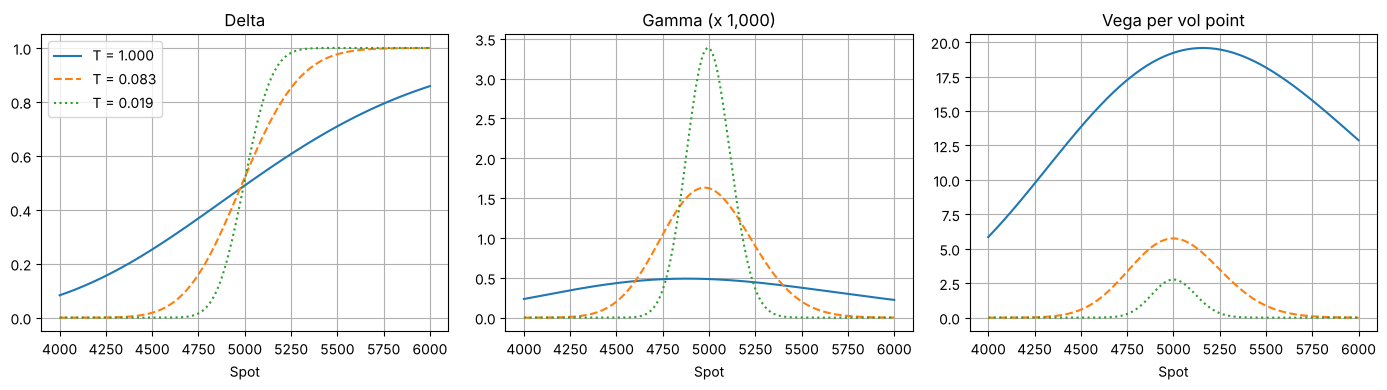

CASE ATM gamma one week before expiry is 7.0 times the one-year gamma


In [2]:
spots = np.linspace(4000, 6000, 201)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for T, ls in [(1.0, "-"), (1 / 12, "--"), (1 / 52, ":")]:
    gs = [bs_greeks(mkt, 5000.0, T, 0.17, call=True, spot=s) for s in spots]
    ax[0].plot(spots, [g["delta"] for g in gs], ls, label=f"T = {T:.3f}")
    ax[1].plot(spots, [g["gamma"] * 1e3 for g in gs], ls)
    ax[2].plot(spots, [g["vega"] for g in gs], ls)
ax[0].set_title("Delta"); ax[1].set_title("Gamma (x 1,000)"); ax[2].set_title("Vega per vol point")
ax[0].legend()
for a in ax:
    a.set_xlabel("Spot")
plt.tight_layout(); plt.show()
g1w = bs_greeks(mkt, 5000.0, 1 / 52, 0.17, spot=5000.0)["gamma"]
g1y = bs_greeks(mkt, 5000.0, 1.0, 0.17, spot=5000.0)["gamma"]
print(f"CASE ATM gamma one week before expiry is {g1w / g1y:.1f} times the one-year gamma")

**Lectura.** Cerca del vencimiento la gamma de una opción en el dinero se dispara y la vega desaparece: el riesgo
pasa de la volatilidad a la posición exacta del spot. Es el *pin risk*: si el índice cierra justo en el strike, el
desk no sabe hasta el último momento si tendrá que entregar el subyacente o no.

### Theta y gamma

Sin carry (tipos, repo y dividendos nulos), la ecuación de Black-Scholes (Hull 19.7) se reduce a
$\Theta = -\tfrac12 \sigma^2 S^2 \Gamma$: el tiempo que pierde una opción es exactamente lo que se gana en
promedio con la gamma si la volatilidad realizada es la implícita. Ser largo gamma cuesta theta.

In [3]:
bare = EquityMarket(flat_curve(0.0), spot=100.0, repo=0.0, divs=[])
g = bs_greeks(bare, 100.0, 0.25, 0.20, call=True)
theta_formula = -0.5 * 0.20 ** 2 * 100.0 ** 2 * g["gamma"] / 365
print(f"CASE zero carry: theta per day {g['theta']:.5f}, -0.5 sigma^2 S^2 gamma / 365 = {theta_formula:.5f}")

CASE zero carry: theta per day -0.02189, -0.5 sigma^2 S^2 gamma / 365 = -0.02183


## 2. Explicación del P&L diario

El banco vendió a la clienta de D01 los 100 contratos del put 90 % (1.000 veces el índice). Un día el índice cae
un 3 % y la volatilidad del strike 4.500 sube 1,5 puntos. La aproximación de Taylor:

$$\Delta V \approx \Delta\,\delta S + \tfrac12\Gamma\,\delta S^2 + \text{vega}\,\delta\sigma + \Theta\,\delta t
+ \text{vanna}\,\delta S\,\delta\sigma + \tfrac12\text{volga}\,\delta\sigma^2$$

se compara con la revaluación completa. El residuo es lo que el *P&L explain* deja sin explicar.

In [4]:
units = -1000.0                                  # bank is short 1,000 index units of the put
K, T = 4500.0, 1.0
vol0 = float(surface.vol_strike(mkt, K, T))
g0 = bs_greeks(mkt, K, T, vol0, call=False)
dS, dvol_pts, dt_days = -0.03 * mkt.spot, 1.5, 1
g1 = bs_greeks(mkt, K, T - dt_days / 365, vol0 + dvol_pts / 100, call=False, spot=mkt.spot + dS)
full = units * (g1["price"] - g0["price"])
terms = {
    "delta": units * g0["delta"] * dS,
    "gamma": units * 0.5 * g0["gamma"] * dS ** 2,
    "vega": units * g0["vega"] * dvol_pts,
    "theta": units * g0["theta"] * dt_days,
    "vanna": units * g0["vanna"] * dS * dvol_pts,
    "volga": units * 0.5 * g0["volga"] * dvol_pts ** 2,
}
explain = pd.DataFrame({"EUR": terms}).T
explain["sum of terms"] = sum(terms.values())
explain["full revaluation"] = full
explain["unexplained"] = full - sum(terms.values())
print(explain.T.map(lambda v: f"{v:,.0f}"))        # 1,000 index units = 1,000 EUR per index point
print(f"CASE short 100 puts, index -3% and vol +1.5: full P&L {full:,.0f} EUR, unexplained {full - sum(terms.values()):,.0f} EUR")

                      EUR
delta             -44,139
gamma              -4,025
vega              -24,946
theta                 381
vanna              -1,324
volga                -173
sum of terms      -74,226
full revaluation  -73,950
unexplained           276
CASE short 100 puts, index -3% and vol +1.5: full P&L -73,950 EUR, unexplained 276 EUR


**Lectura.** Sin cubrir, el banco pierde por delta (es corto un put: largo índice), por gamma (corto convexidad) y
por vega. Vanna y volga son pequeños pero no despreciables con movimientos grandes; el residuo restante es de
tercer orden. Un desk con muchas opciones exige que el residuo sea pequeño cada día: si no lo es, falta un riesgo
en el sistema.

## 3. Cobertura delta: de dónde sale el P&L

Quien compra una opción y cubre la delta cada día gana, en cada intervalo,
$$\text{P\&L}_i \approx \tfrac12\,\Gamma_i S_i^2\left(r_i^2 - \sigma_{\text{imp}}^2\,\delta t\right)$$
donde $r_i$ es el rendimiento realizado. Si la volatilidad realizada coincide con la implícita, el P&L esperado es
cero; si es mayor, gana el largo gamma. Se simula una call a tres meses (spot 100, sin carry, implícita 20 %) con
4.000 caminos.

In [5]:
T3, K3, imp = 0.25, 100.0, 0.20
premium = bs_price(100.0, K3, T3, imp, 1.0)
cases = []
for realised in [0.20, 0.25]:
    paths = simulate_gbm(100.0, 0.0, realised, T3, 63, 4000, seed=12)
    for label, kwargs in [("daily, hedge at implied", {}),
                          ("weekly, hedge at implied", {"rebalance_every": 5}),
                          ("daily, hedge at realised", {"hedge_vol": realised}),
                          ("daily, 5 bp costs", {"cost_bp": 5.0}),
                          ("weekly, 5 bp costs", {"rebalance_every": 5, "cost_bp": 5.0})]:
        pnl = delta_hedge_pnl(paths, K3, T3, imp, **kwargs)
        cases.append({"realised": realised, "strategy": label, "mean": pnl.mean(), "stdev": pnl.std()})
res = pd.DataFrame(cases)
print(f"premium at 20%: {premium:.3f}; BS(25%) - BS(20%) = {bs_price(100.0, K3, T3, 0.25, 1.0) - premium:.3f}")
print(res.to_string(index=False, formatters={"realised": "{:.0%}".format, "mean": "{:.3f}".format, "stdev": "{:.3f}".format}))
r25 = res[(res.realised == 0.25)].set_index("strategy")
print(f"CASE bought at 20%, realised 25%: mean P&L {r25.loc['daily, hedge at implied', 'mean']:.2f} "
      f"(stdev {r25.loc['daily, hedge at implied', 'stdev']:.2f} hedging at implied, {r25.loc['daily, hedge at realised', 'stdev']:.2f} at realised)")

premium at 20%: 3.988; BS(25%) - BS(20%) = 0.996
realised                 strategy   mean stdev
     20%  daily, hedge at implied  0.007 0.435
     20% weekly, hedge at implied -0.003 0.933
     20% daily, hedge at realised  0.007 0.435
     20%        daily, 5 bp costs -0.145 0.433
     20%       weekly, 5 bp costs -0.085 0.928
     25%  daily, hedge at implied  1.007 0.681
     25% weekly, hedge at implied  0.997 1.240
     25% daily, hedge at realised  1.004 0.543
     25%        daily, 5 bp costs  0.842 0.645
     25%       weekly, 5 bp costs  0.910 1.228
CASE bought at 20%, realised 25%: mean P&L 1.01 (stdev 0.68 hedging at implied, 0.54 at realised)


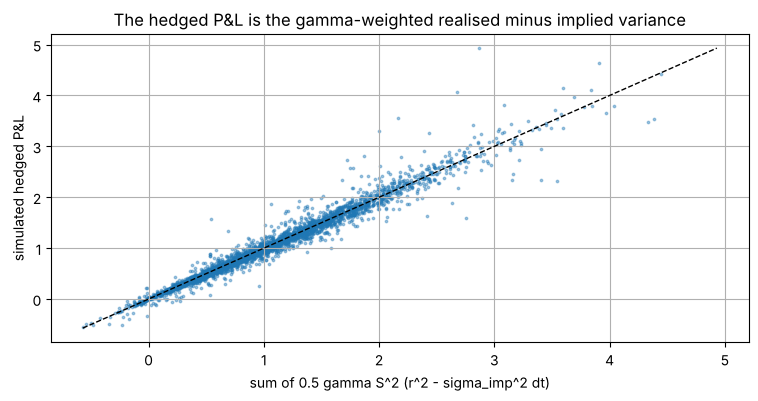

CASE correlation between the gamma P&L formula and the simulated P&L: 0.982


In [6]:
paths = simulate_gbm(100.0, 0.0, 0.25, T3, 63, 4000, seed=12)
pnl = delta_hedge_pnl(paths, K3, T3, imp)
dtau = T3 / 63
approx = np.zeros(len(paths))
for i in range(63):
    tau = T3 - i * dtau
    S = paths[:, i]
    d1 = (np.log(S / K3) + 0.5 * imp ** 2 * tau) / (imp * np.sqrt(tau))
    gamma = norm.pdf(d1) / (S * imp * np.sqrt(tau))
    ret = paths[:, i + 1] / S - 1
    approx += 0.5 * gamma * S ** 2 * (ret ** 2 - imp ** 2 * dtau)
plt.scatter(approx, pnl, s=3, alpha=0.4)
lim = [min(approx.min(), pnl.min()), max(approx.max(), pnl.max())]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("sum of 0.5 gamma S^2 (r^2 - sigma_imp^2 dt)"); plt.ylabel("simulated hedged P&L")
plt.title("The hedged P&L is the gamma-weighted realised minus implied variance"); plt.show()
corr = np.corrcoef(approx, pnl)[0, 1]
print(f"CASE correlation between the gamma P&L formula and the simulated P&L: {corr:.3f}")

**Lectura.**

- Con cobertura a la implícita el beneficio medio es el que da la fórmula, pero depende del camino: se gana más si
  el índice se mueve cerca del strike, donde la gamma es alta.
- Cubrir con la delta de la volatilidad realizada (si se conociera) fijaría el resultado en BS(25 %) − BS(20 %)
  con rebalanceo continuo. Con rebalanceo diario queda el ruido de discretizar, el mismo que aparece cuando la
  realizada coincide con la implícita (0,43 a 20 %, unos 0,54 a 25 %).
- Rebalancear cada semana duplica la dispersión (de 0,43 a 0,93) y ahorra costes (con 5 pb por operación, de 0,15
  a 0,09 por opción). Aquí el coste extra de cubrir a diario es pequeño frente al riesgo que elimina; con costes
  más altos o gamma más alta el equilibrio cambia, y el desk elige la frecuencia mirando las dos cosas.

## 4. Caso: el plan de opciones de empleados de una empresa cotizada

**Situación.** *Hogar y Cuidado SA* (empresa ficticia, con los parámetros del caso PHC de Myint & Famery, cap. 42)
ha concedido a sus empleados un millón de opciones americanas *liquidadas con entrega física*, con strike igual al
spot de 28 €, tres años de bloqueo (*lock-up*) y siete de vencimiento. Datos del apéndice 42.1: tipo 0,04 %,
rentabilidad por dividendo 2,6 %, volatilidad 35,7 %, árbol de 700 pasos.

**Riesgos.** Si las opciones se ejercen, la empresa tiene que emitir acciones (dilución) o entregar acciones
compradas en mercado a un precio alto (riesgo económico). La empresa compara: (1) no hacer nada; (2) recomprar ya
el millón de acciones; (3) comprar al banco opciones espejo (*mirror options*) con los mismos términos.

CASE employee option: 7.866 EUR = 28.1% of spot (Myint: 28.1%); European 25.6%; plan value 7.87 M EUR


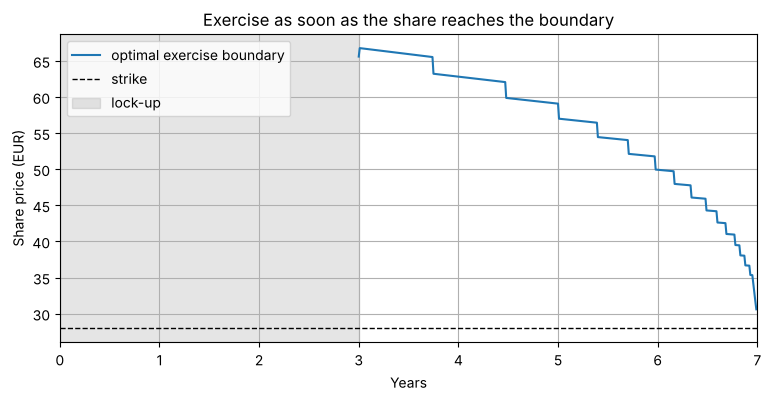

Boundary just after lock-up 65.6 EUR; one year before expiry 49.9 EUR


In [7]:
r_esop, q_esop, vol_esop, S0, K_esop, T_esop, lock, N_opt, wacc = 0.0004, 0.026, 0.357, 28.0, 28.0, 7.0, 3.0, 1e6, 0.08
esop_mkt = EquityMarket(flat_curve(r_esop), spot=S0, repo=q_esop, divs=[])   # continuous dividend yield as "repo"
value, b_times, b_spots = binomial(esop_mkt, K_esop, T_esop, vol_esop, 700, call=True, american=True,
                                   exercise_from=lock, return_boundary=True)
european = binomial(esop_mkt, K_esop, T_esop, vol_esop, 700, call=True)
print(f"CASE employee option: {value:.3f} EUR = {value / S0:.1%} of spot (Myint: 28.1%); European {european / S0:.1%}; "
      f"plan value {value * N_opt / 1e6:.2f} M EUR")
log_b = np.log(b_spots)
smooth = np.exp(np.r_[log_b[0], 0.5 * (log_b[1:] + log_b[:-1])])      # the CRR boundary alternates between node sets
plt.plot(b_times, smooth, label="optimal exercise boundary")
plt.axhline(K_esop, color="k", ls="--", lw=1, label="strike")
plt.axvspan(0, lock, color="grey", alpha=0.2, label="lock-up")
plt.xlim(0, 7); plt.xlabel("Years"); plt.ylabel("Share price (EUR)"); plt.legend()
plt.title("Exercise as soon as the share reaches the boundary"); plt.show()
print(f"Boundary just after lock-up {smooth[0]:.1f} EUR; one year before expiry {smooth[np.searchsorted(b_times, 6.0)]:.1f} EUR")

La frontera de ejercicio es alta al terminar el bloqueo (unos 66 €, más del doble del strike) y baja hacia el
strike al acercarse el vencimiento. Se ejerce antes de tiempo porque el titular de la opción no cobra dividendos:
con una rentabilidad del 2,6 % y tipos casi nulos, una opción muy dentro del dinero pierde más dividendo que el
valor temporal que conserva.

Ahora se simulan 40.000 caminos neutrales al riesgo, se aplica la frontera y se mide el coste de cada estrategia
para la empresa, incluido el coste de financiar a un WACC del 8 % lo que se paga por adelantado (como en la
tabla de Myint).

In [8]:
steps = 700
dt = T_esop / steps
paths = simulate_gbm(S0, r_esop - q_esop, vol_esop, T_esop, steps, 40000, seed=8)
bound = np.full(steps + 1, np.inf)
bound[np.round(b_times / dt).astype(int)] = np.where(np.isnan(smooth), np.inf, smooth)
bound[-1] = K_esop

def exercise_times(paths, bound):
    hit = paths >= bound[None, :]
    hit[:, :int(round(lock / dt))] = False
    exercised = hit.any(axis=1)
    first = np.where(exercised, hit.argmax(axis=1), steps)
    return first, paths[np.arange(len(paths)), first], exercised

first, S_tau, ex = exercise_times(paths, bound)
tau = first * dt
payout = np.where(ex, S_tau - K_esop, 0.0)
div_saved = np.hstack([np.zeros((len(paths), 1)), np.cumsum(q_esop * paths[:, :-1] * dt, axis=1)])[np.arange(len(paths)), first]
costs = {
    "1. do nothing": payout,
    "2. share buy-back": S0 - (np.where(ex, K_esop, S_tau) + div_saved) + S0 * ((1 + wacc) ** tau - 1),
    "3. mirror options": value + value * ((1 + wacc) ** tau - 1),
}
summary = pd.DataFrame({k: {"expected cost": v.mean(), "cost at 95%": np.quantile(v, 0.95), "cost at 5%": np.quantile(v, 0.05)}
                        for k, v in costs.items()}).T * N_opt / 1e6
summary["of which funding (WACC)"] = [0.0, (S0 * ((1 + wacc) ** tau - 1)).mean() * N_opt / 1e6,
                                      (value * ((1 + wacc) ** tau - 1)).mean() * N_opt / 1e6]
print("M EUR")
print(summary.round(1))
print(f"CASE exercised before expiry in {ex.mean():.0%} of paths; expected payout {payout.mean() * N_opt / 1e6:.2f} M EUR "
      f"(tree value {value * N_opt / 1e6:.2f} M); do-nothing cost at 95% {summary.loc['1. do nothing', 'cost at 95%']:.1f} M EUR")

M EUR
                   expected cost  cost at 95%  cost at 5%  of which funding (WACC)
1. do nothing                7.9         39.5         0.0                      0.0
2. share buy-back           26.0         42.7         4.4                     18.2
3. mirror options           13.0         13.5        10.1                      5.1
CASE exercised before expiry in 29% of paths; expected payout 7.95 M EUR (tree value 7.87 M); do-nothing cost at 95% 39.5 M EUR


**Lectura** (compárese con la tabla 42.1 de Myint: 7,9 / 28,7 / 13,7 M€ de coste total).

- Sin financiación, las tres estrategias cuestan lo mismo en media, alrededor del valor de la opción.
- No hacer nada no cuesta nada por adelantado, pero en el 5 % de los peores escenarios cuesta más de 39 M€.
- La recompra cubre la dilución si se ejerce, pero si no se ejerce deja a la empresa con autocartera que vale menos
  de lo que pagó, y además inmoviliza 28 M€ al WACC durante años.
- Las opciones espejo eliminan la dilución y el riesgo económico por 7,9 M€ de prima más su financiación. Es la
  recomendación de Myint: el coste esperado es parecido y la cola desaparece.

En la práctica los empleados ejercen antes de lo óptimo (apéndice 42.2 de Myint: por ejemplo, en cuanto la acción
supera en un 30 % el strike). Eso abarata el plan para la empresa.

In [9]:
b_sub = np.full(steps + 1, 1.3 * K_esop)
b_sub[-1] = K_esop
first_s, S_s, ex_s = exercise_times(paths, b_sub)
payout_sub = np.where(ex_s, S_s - K_esop, 0.0)
print(f"CASE exercise at 130% of strike: expected payout {payout_sub.mean() * N_opt / 1e6:.2f} M EUR vs {payout.mean() * N_opt / 1e6:.2f} M optimal; "
      f"average exercise after {(first_s[ex_s] * dt).mean():.1f} years")

CASE exercise at 130% of strike: expected payout 7.13 M EUR vs 7.95 M optimal; average exercise after 3.7 years


### El lado del banco: quien vende las opciones espejo

El banco queda corto un millón de opciones americanas a siete años sobre una acción individual. Las griegas por
revaluación del árbol muestran qué tiene que cubrir y qué no puede cubrir del todo.

In [10]:
def esop_value(spot=S0, vol=vol_esop, q=q_esop):
    m_ = EquityMarket(flat_curve(r_esop), spot=spot, repo=q, divs=[])
    return binomial(m_, K_esop, T_esop, vol, 700, call=True, american=True, exercise_from=lock)

h = 0.01 * S0
delta_b = -(esop_value(S0 + h) - esop_value(S0 - h)) / (2 * h) * N_opt
hg = 0.05 * S0                    # wider bump for gamma: CRR values jump as nodes cross the strike
gamma_b = -(esop_value(S0 + hg) - 2 * value + esop_value(S0 - hg)) / hg ** 2 * N_opt
vega_b = -(esop_value(vol=vol_esop + 0.01) - esop_value(vol=vol_esop - 0.01)) / 2 * N_opt
div_b = -(esop_value(q=q_esop + 0.001) - esop_value(q=q_esop - 0.001)) / 2 * N_opt
print(f"Bank short 1M mirror options: delta {delta_b:,.0f} shares (buys about {-delta_b:,.0f} shares to hedge)")
print(f"gamma {gamma_b * 0.01 * S0:,.0f} shares per 1% move; vega {vega_b / 1e3:,.0f} k EUR per vol point; "
      f"dividend yield +10 bp: {div_b / 1e3:+,.0f} k EUR")
margin = (esop_value(vol=vol_esop + 0.02) - value) * N_opt
print(f"CASE a 2-point vol margin on 7y single-stock vol adds {margin / 1e6:.2f} M EUR ({margin / (value * N_opt):.0%}) to the premium")

Bank short 1M mirror options: delta -569,782 shares (buys about 569,782 shares to hedge)
gamma -3,611 shares per 1% move; vega -246 k EUR per vol point; dividend yield +10 bp: +74 k EUR
CASE a 2-point vol margin on 7y single-stock vol adds 0.49 M EUR (6%) to the premium


**Lectura.** El banco compra acciones para cubrir la delta y la rebalancea (corto gamma: compra cuando sube, vende
cuando baja). La vega a siete años sobre una acción individual apenas se negocia, así que el banco cobra un margen
de volatilidad y reserva por el riesgo que se queda. También es largo dividendos: si la empresa sube el dividendo,
la opción que ha vendido vale menos. Y tiene riesgo de crédito con la empresa durante siete años (B4).

## 5. Comprobaciones

In [11]:
assert abs(g["theta"] / theta_formula - 1) < 0.01
assert abs(full - sum(terms.values())) < 0.02 * abs(full)
r20 = res[res.realised == 0.20].set_index("strategy")
assert abs(r20.loc["daily, hedge at implied", "mean"]) < 0.05 * premium
assert r20.loc["daily, hedge at implied", "stdev"] < r20.loc["weekly, hedge at implied", "stdev"]
assert r25.loc["daily, hedge at realised", "stdev"] < r25.loc["daily, hedge at implied", "stdev"]
assert corr > 0.9
assert abs(value / S0 - 0.281) < 0.003
assert abs(payout.mean() / value - 1) < 0.03
assert summary.loc["3. mirror options", "cost at 95%"] < summary.loc["1. do nothing", "cost at 95%"]
assert payout_sub.mean() < payout.mean()
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuántos futuros sobre el índice (multiplicador 10 €) tiene que comprar o vender el banco para cubrir
   la delta de los 100 puts vendidos?
2. **Intermedio.** Repite el *P&L explain* para un día en que el índice sube un 2 % y la volatilidad baja 1 punto.
3. **Avanzado.** La empresa se plantea una cuarta estrategia: comprar ella misma la delta de las opciones (con la
   delta Black-Scholes de la europea a siete años) y rebalancear cada 0,1 años (unas cinco semanas), financiando
   las acciones al WACC.
   Estima el coste esperado y el coste al 95 % y compáralos con las opciones espejo.

## Soluciones

In [12]:
position_delta = units * g0["delta"]                     # EUR per index point (1,000 units short a put of delta < 0)
n_futures = position_delta / 10.0                         # each future is worth 10 EUR per point
print(f"Short put book: delta {position_delta:,.0f} EUR per point (long the index) -> sell {n_futures:,.0f} futures")
print("Check: 100 contracts x 10 EUR x |put delta| = " f"{100 * 10 * abs(g0['delta']) / 10:,.0f} futures")

Short put book: delta 294 EUR per point (long the index) -> sell 29 futures
Check: 100 contracts x 10 EUR x |put delta| = 29 futures


In [13]:
g_up = bs_greeks(mkt, K, T - 1 / 365, vol0 - 0.01, call=False, spot=mkt.spot * 1.02)
dS2, dv2 = 0.02 * mkt.spot, -1.0
full2 = units * (g_up["price"] - g0["price"])
approx2 = units * (g0["delta"] * dS2 + 0.5 * g0["gamma"] * dS2 ** 2 + g0["vega"] * dv2 + g0["theta"]
                   + g0["vanna"] * dS2 * dv2 + 0.5 * g0["volga"] * dv2 ** 2)
print(f"index +2%, vol -1: full {full2:,.0f} EUR, Taylor {approx2:,.0f} EUR, unexplained {full2 - approx2:,.0f} EUR")

index +2%, vol -1: full 43,884 EUR, Taylor 43,984 EUR, unexplained -100 EUR


In [14]:
monthly = paths[:, ::10]                               # rebalance every 10 tree steps = 0.1 years (about five weeks)
n_m = monthly.shape[1] - 1
dtm = T_esop / n_m
t_m = np.arange(n_m + 1) * dtm
hedge_pnl = np.zeros(len(paths))
alive = np.ones(len(paths), dtype=bool)
stop = np.minimum(np.ceil(first / 10).astype(int), n_m)  # stop hedging at the first rebalancing date after exercise
for i in range(n_m):
    tau_left = T_esop - t_m[i]
    S = monthly[:, i]
    F = S * np.exp((r_esop - q_esop) * tau_left)
    d1 = (np.log(F / K_esop) + 0.5 * vol_esop ** 2 * tau_left) / (vol_esop * np.sqrt(tau_left))
    shares = np.exp(-q_esop * tau_left) * norm.cdf(d1) * (i < stop)
    gain = shares * (monthly[:, i + 1] - S + q_esop * S * dtm) - shares * S * wacc * dtm
    hedge_pnl += gain
cost_self = payout - hedge_pnl
print(f"self delta hedge: expected cost {cost_self.mean() * N_opt / 1e6:.1f} M EUR, at 95% {np.quantile(cost_self, 0.95) * N_opt / 1e6:.1f} M EUR "
      f"vs mirror options {summary.loc['3. mirror options', 'expected cost']:.1f} / {summary.loc['3. mirror options', 'cost at 95%']:.1f} M EUR")
print(f"The self hedge cuts the cost at 95% from {np.quantile(payout, 0.95) * N_opt / 1e6:.1f} M EUR (do nothing) and costs less than the")
print("buy-back, but monthly-ish rebalancing leaves gamma and vol risk with the company, needs a trading capability")
print("and may be restricted by the rules on trading in own shares (buy-back programmes, market abuse).")

self delta hedge: expected cost 13.4 M EUR, at 95% 23.0 M EUR vs mirror options 13.0 / 13.5 M EUR
The self hedge cuts the cost at 95% from 39.5 M EUR (do nothing) and costs less than the
buy-back, but monthly-ish rebalancing leaves gamma and vol risk with the company, needs a trading capability
and may be restricted by the rules on trading in own shares (buy-back programmes, market abuse).
